# Exploratory Data Analysis: FAERS Drug Names

This notebook explores drug names from 5,000 FDA Adverse Event Reporting System (FAERS) reports received in 2025, pulled from the openFDA API with `pull_faers.py`. Run that script first to create `faers_drug_names.csv`.

**Goal:** understand how messy real-world drug names are, and how often openFDA fails to match them to an RxNorm code (RxCUI).

In [70]:
# Import Libraries
import pandas as pd
import matplotlib.pyplot as plt

In [71]:
# Load and view 15 records of the dataset
df = pd.read_csv("faers_drug_names.csv")
df.head(15)

,report_id,raw_name,rxcui,generic_name,brand_name
0,10144708,DEMEROL,860792|861463|861473|861493|861494|861522|8615...,MEPERIDINE HYDROCHLORIDE,DEMEROL
1,10144708,ACIPHEX,854868|854870,RABEPRAZOLE SODIUM,ACIPHEX
2,10144708,ECOTRIN,308416|1189781,ASPIRIN,ECOTRIN
3,10144708,CELEBREX,205322|205323|213468|213469|349514|352314|6863...,CELECOXIB,CELEBREX
4,10144708,ZYRTEC,1014674|1020022,CETIRIZINE HYDROCHLORIDE,ZYRTEC
5,10144708,UNSPECIFIED INGREDIENT,NaN,NaN,NaN
6,10144708,GLUCOTROL,310489|314006|315107|865568|865571|865573,GLIPIZIDE,GLUCOTROL XL
7,10144708,IRON,NaN,IRON,FERRUM METALLICUM 6X|FERRUM METALLICUM|REAL SU...
8,10144708,LIPITOR,259255|262095|617310|617311|617312|617314|6173...,ATORVASTATIN CALCIUM,LIPITOR
9,10144708,OMEGA 3,NaN,NaN,NaN


Each row is one drug mentioned in one adverse event report, so a single report can have many rows (report 10144708 lists 15 drugs). `raw_name` is the drug as the reporter typed it. `rxcui`, `generic_name` and `brand_name` are what openFDA matched it to, and are blank when matching failed.

Drugs often have many RxCUIs (Demerol has a long list) because RxNorm gives each specific product, dose and form its own code. Reporters rarely say which product they mean, so this project maps names at the **ingredient level** (Demerol → meperidine).

In [72]:
# Standardizing the raw_name column to all Upper case, strip leading and trailing spaces, and any spaces in the middle greater than 1 space.
df["clean_name"] =  df["raw_name"].str.upper().str.strip().str.replace(r"\s+", " ", regex=True)

In [73]:
# Dropping duplicates and viewing the number of unique names after standardization
# Viewing number of unique names with no rxcui match 
unique = df.drop_duplicates("clean_name")
print("Unique names:", len(unique))
print("Unique names with no match:", unique["rxcui"].isna().sum())

unique[unique["rxcui"].isna()]["clean_name"].sample(30, random_state=1)

Unique names: 2605
Unique names with no match: 1110


2777                                ATROPINE\DIPHENOXYLATE
6683                                            SENNA LEAF
914                                      CALCIUM ASCORBATE
10239                                            DIAMICRON
1956                                                TRUQAP
5023                      ELEXACAFTOR\IVACAFTOR\TEZACAFTOR
12908    HUMAN IMMUNOGLOBULIN G\HYALURONIDASE RECOMBINA...
15735                                              RIFATER
20561                                            FASTURTEC
943                  HAIR KERATIN AMINO ACIDS GOLD COMPLEX
7486                            DIETARY SUPPLEMENT\HERBALS
2011                                              DERMATOP
740                                                CALONAL
12154                                            ROBAXACET
16496                          HERBALS\PLANTAGO OVATA LEAF
16236                                           SELADELPAR
11619                                             REACTI

After standardizing, there are 2,605 unique drug names, and **1,110 (43%) have no RxCUI**.

The sample of unmatched names shows several failure types:
- US brand names openFDA missed (Truqap, Lumify, Rogaine)
- Non-US brand names (Calonal, Diamicron, Polaramine)
- Plain generics that still failed (Calcitonin, Defibrotide)
- Abbreviations and extra text (Venlafaxine HCL, Lamotrigine Extended Release)
- Combination products separated by `\` (Furosemide\Spironolactone)
- Foreign-language names (Oxycodon HCL/Naloxon HCL Puren, German)
- Supplements and non-drugs, where "no code" may be correct (Senna Leaf, Dietary Supplement\Herbals)

Not every unmatched name is a failure: some correctly have no prescribable RxNorm code.

In [74]:
unmatched = unique[unique["rxcui"].isna()]

print("Unmatched names:", len(unmatched))
print("...but with a generic name filled in:", unmatched["generic_name"].notna().sum())

unmatched[unmatched["generic_name"].notna()][["clean_name", "generic_name"]].head(20)

Unmatched names: 1110
...but with a generic name filled in: 35


,clean_name,generic_name
7,IRON,IRON
66,CALCIUM,CALCIUM
67,MAGNESIUM,MAGNESIUM
435,CINNAMON,CINNAMON
714,VITAMIN E,VITAMIN E
717,QUERCETIN,"QUERCETIN|QUERCETIN,"
738,HYALURONATE SODIUM,HYALURONATE SODIUM
799,ANTICOAGULANT SODIUM CITRATE,TRISODIUM CITRATE DIHYDRATE
942,GOLD,GOLD
987,VITAMIN C,VITAMIN C


Of the 1,110 unmatched names, only **35 had a generic name**. These were mostly supplements (iron, vitamin C, melatonin), where "no code" is likely correct, plus a few real hospital drugs such as contrast agents (Visipaque → iodixanol, Omnipaque → iohexol) that need checking in RxNav.

The other **1,075 (97%) weren't identified by openFDA at all**: no code and no generic name. This is the gap the tool is meant to close.

In [75]:
# Number of records that matched after standardizations
spellings = df.groupby("clean_name")["raw_name"].nunique()
spellings[spellings > 1]

clean_name
REACTINE    2
SOLUPRED    2
Name: raw_name, dtype: int64

In [76]:
# Displaying the raw_name and clean_name for for the 2 records that were updated with the standardization
df[df["clean_name"].isin(["REACTINE", "SOLUPRED"])][["raw_name", "clean_name"]].drop_duplicates()

,raw_name,clean_name
2865,SOLUPRED,SOLUPRED
9486,Solupred,SOLUPRED
11619,Reactine,REACTINE
16515,REACTINE,REACTINE


Standardizing case and spacing merged only **2 names**, both capitalization differences (Solupred/SOLUPRED, Reactine/REACTINE). Formatting is not the problem in this data; the difficulty is in the names themselves (brands, typos, foreign names), so simple text cleaning won't solve it.

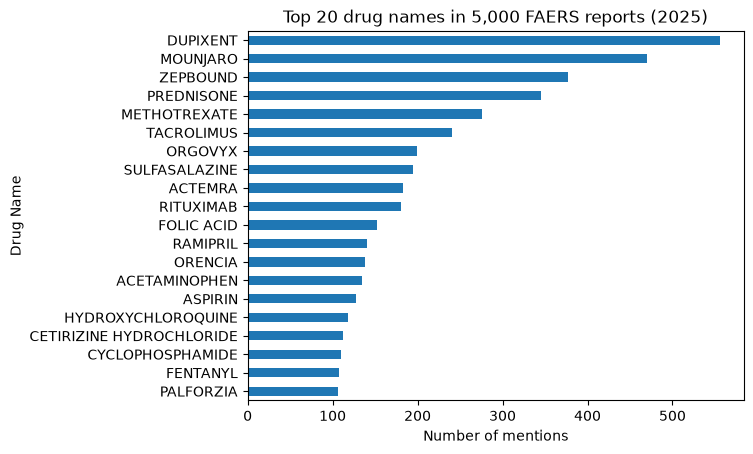

In [77]:
# Pulling the top 20 Drug names in the FAERS report
# Displaying a bar chart with the drug names and counts 
drug_counts = df["clean_name"].value_counts()
drug_counts.head(20).sort_values().plot(
    kind="barh",
    title="Top 20 drug names in 5,000 FAERS reports (2025)",
    xlabel="Number of mentions",
    ylabel="Drug Name");



The most common names are a mix of brands (Dupixent, Mounjaro) and generics (prednisone, methotrexate), so the tool must handle both. Mounjaro and Zepbound are the same ingredient (tirzepatide) under two brand names, another reason to map at the ingredient level.

There's also a large cluster of rheumatoid arthritis drugs (methotrexate, sulfasalazine, Actemra, rituximab, Orencia, hydroxychloroquine), since RA patients often take several at once.

**Limitation:** the script pulled the first 5,000 reports the API returned for 2025, not a random sample, so some drugs may be over-represented.